# Классификация тональности отзывов IMDB — 1. EDA

**Задача:** бинарная классификация отзывов о фильмах на позитивные / негативные.

**Данные:** [IMDB Dataset of 50K Movie Reviews (Kaggle)](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews) — 50 000 отзывов, колонки `review` (текст) и `sentiment` (`positive` / `negative`).

Решение построено по [шаблону](https://github.com/EliseevVadim/hallucinations-detection) и разбито на три ноутбука:

| Ноутбук | Содержание |
|---|---|
| **`eda.ipynb`** (этот) | загрузка, очистка, анализ текстов и токенов |
| `baseline.ipynb` | бейзлайн (Count / TF-IDF / Hashing + классификаторы) и отбор токенов |
| `neural_networks.ipynb` | нейросети с нуля, готовые эмбеддинги GloVe, предобученные модели, итоговое сравнение и выводы |

Вспомогательный код — в пакете `core/` (адаптированные модули шаблона): `data`, `nlp`, `vectorization`, `nn_models`, `nn_training`, `baseline_training`, `training_results`, `visualization`, `utils`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from core.data import SEED, load_imdb, split_imdb, split_validation
from core.utils import init_random_seed, get_device
import core.visualization as p

init_random_seed(SEED)
sns.set_theme(style="whitegrid")

from core.nlp import tokenize, token_counts, stopwords_counts, count_based_analysis, SENTIMENT_KEEP_WORDS

## 1. Загрузка и очистка

- удаляем HTML-переносы `<br />` (иначе `br` становится одним из самых частых «слов»);
- удаляем дубликаты отзывов;
- по ТЗ оставляем тексты не короче 10 слов.

In [2]:
df = load_imdb()
df.head()

всего: 50000 (min слов: 4) | без дубликатов: 49582 | после фильтра >= 10 слов: 49577 (min слов: 10)


,review,sentiment,n_words,label
0,One of the other reviewers has mentioned that ...,positive,304,1
1,A wonderful little production. The filming t...,positive,156,1
2,I thought this was a wonderful way to spend ti...,positive,164,1
3,Basically there's a family where a little boy ...,negative,135,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,225,1


## 2. Баланс классов и длины текстов

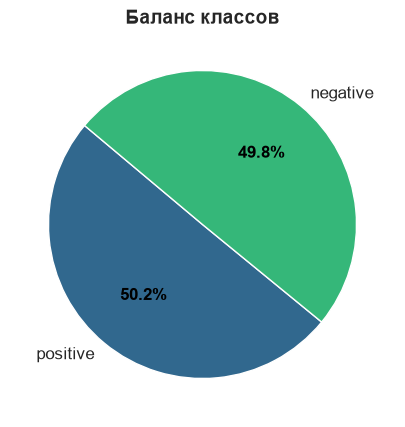

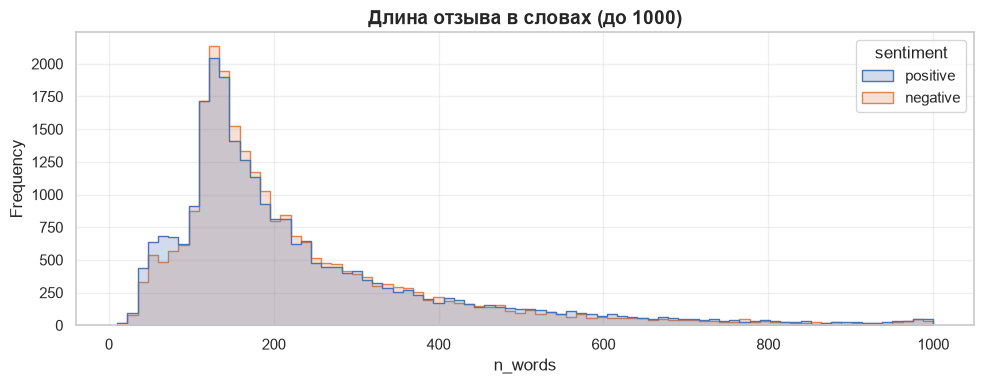

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24693.0,227.3,163.3,10.0,127.0,173.0,276.0,1491.0
positive,24884.0,230.9,175.9,10.0,124.0,171.0,281.0,2459.0


In [3]:
p.plot_pie_chart(df, "sentiment", "Баланс классов")
p.plot_histogram_numeric(df, "n_words", hue="sentiment", x_max=1000, title="Длина отзыва в словах (до 1000)")
df.groupby("sentiment")["n_words"].describe().round(1)

Классы сбалансированы (24 884 positive / 24 693 negative, ≈ 50/50), поэтому accuracy — корректная метрика, а F1 почти с ней совпадает. Распределение длин сильно скошено вправо: медиана ~172 слова, 75-й перцентиль ~280, максимум ~2 460. Для нейросетей ограничим длину последовательности 400 токенами (обрезается ~14% отзывов), для трансформера — 256 субтокенами. Длина почти не отличается между классами — сама по себе она не информативна.

## 3. Токены: стоп-слова и частые слова

Токенизация (`core.nlp.tokenize`): нижний регистр, слова и числа, отрицание `n't` выделяется в отдельный токен, `!` и `?` сохраняются — они тоже несут эмоцию.

всего токенов: 11770196 | уникальных: 106132


доля стоп-слов (NLTK) среди токенов: 46.8%
отрицания и усилители, которые входят в список стоп-слов: ['against', 'aren', 'but', 'couldn', 'didn', 'doesn', 'don', 'few', 'hadn', 'hasn', 'haven', 'isn', 'more', 'most', 'no', 'nor', 'not', 'off', 'only', 'out', 'shouldn', 'too', 'very', 'wasn', 'weren', 'won', 'wouldn']


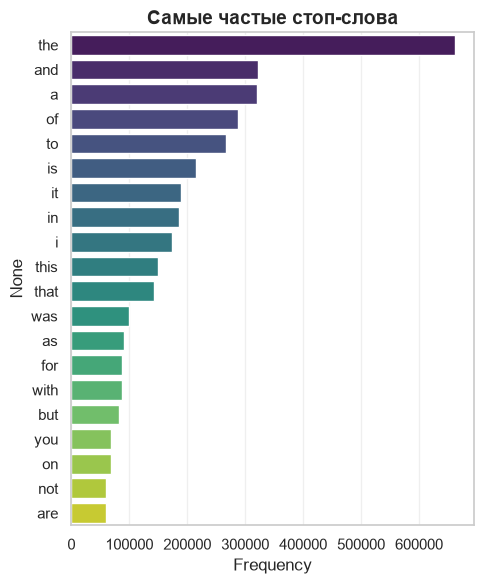

In [4]:
df["tokens"] = df["review"].map(tokenize)
df["n_tokens"] = df["tokens"].str.len()
print("всего токенов:", df["n_tokens"].sum(), "| уникальных:", len(set(t for ts in df["tokens"] for t in ts)))

sw = stopwords_counts(df, "tokens")
print(f"доля стоп-слов (NLTK) среди токенов: {sw.sum() / df['n_tokens'].sum():.1%}")
neg_in_sw = sorted(set(sw.index) & SENTIMENT_KEEP_WORDS)
print("отрицания и усилители, которые входят в список стоп-слов:", neg_in_sw)
p.barplot(sw, "Самые частые стоп-слова", "", top_n=20)

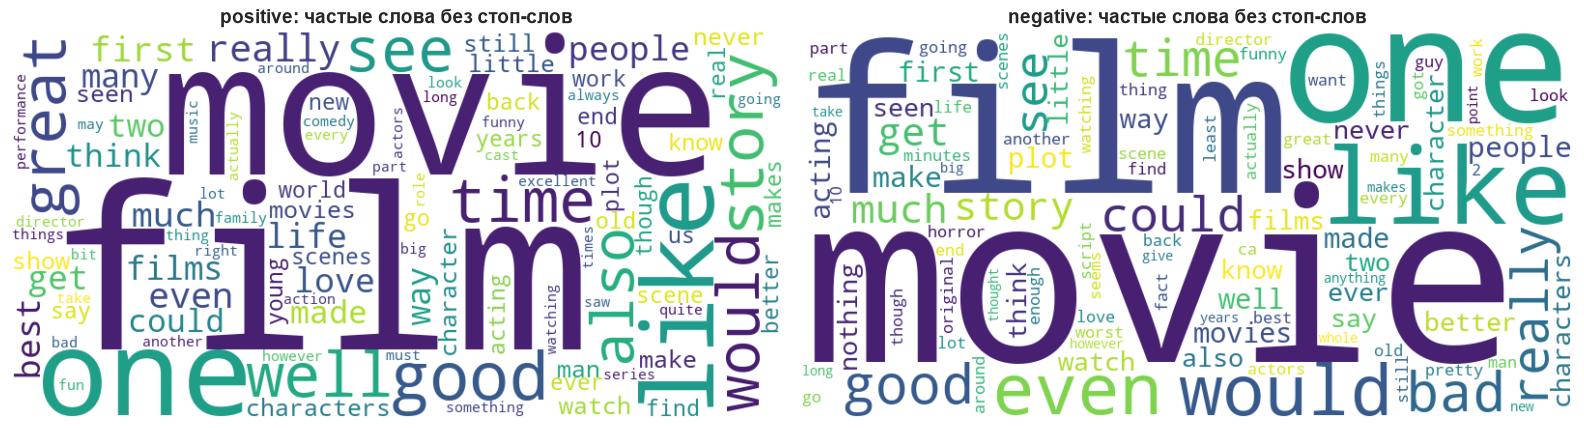

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (label, name) in zip(axes, [(1, "positive"), (0, "negative")]):
    tc = token_counts(df[df["label"] == label], "tokens", remove_stopwords=True, remove_punctuation=True)
    tc = tc[~tc.index.str.startswith("'") & (tc.index != "n't")]   # служебные куски 's, 've, n't
    p.plot_wordcloud(tc, title=f"{name}: частые слова без стоп-слов", ax=ax)
plt.tight_layout()
plt.show()

- Стоп-слова (список NLTK) — почти половина всех токенов (46.8%). Но в список входят **отрицания и усилители** (*not, no, nor, but, very, too, didn, wasn, …*) — для тональности они важны, поэтому стоп-слова не стоит удалять «вслепую» (проверяется в `baseline.ipynb`).
- В облаках слов обоих классов доминируют одни и те же слова — *movie, film, one, like, good, story*: самые частые слова почти не разделяют классы (*good* частое и в негативных отзывах — «not good», «good actors, but…»). Различия видны на оценочных словах: *great, best, love* против *bad, worst, nothing*.

## 4. Какие токены разделяют классы

Функция шаблона `count_based_analysis` для каждой n-граммы (униграммы и биграммы) считает статистику связи с классом (здесь χ²), частоты в каждом классе и логарифм отношения частот (log ratio > 0 — «позитивная» n-грамма).

In [6]:
ngrams = count_based_analysis(df["tokens"].tolist(), df["label"].tolist(), n=2, metric="chi2", min_count=20)
print("n-грамм с частотой >= 20:", len(ngrams))
ngrams.head(20)[["token", "metric", "count_0", "count_1", "log_ratio"]].round(3)

n-грамм с частотой >= 20: 81233


,token,metric,count_0,count_1,log_ratio
0,bad,6487.162,14514,3711,-1.368
1,?,5217.680,22441,9629,-0.851
2,worst,3689.516,4831,441,-2.396
3,great,3282.232,5121,12876,0.917
4,the worst,2988.555,3798,310,-2.507
5,n't,2615.247,39404,26527,-0.400
6,and,2559.248,146065,176016,0.182
7,awful,2326.408,3106,303,-2.329
8,waste,2113.042,2580,177,-2.679
9,no,1840.685,15877,9182,-0.552


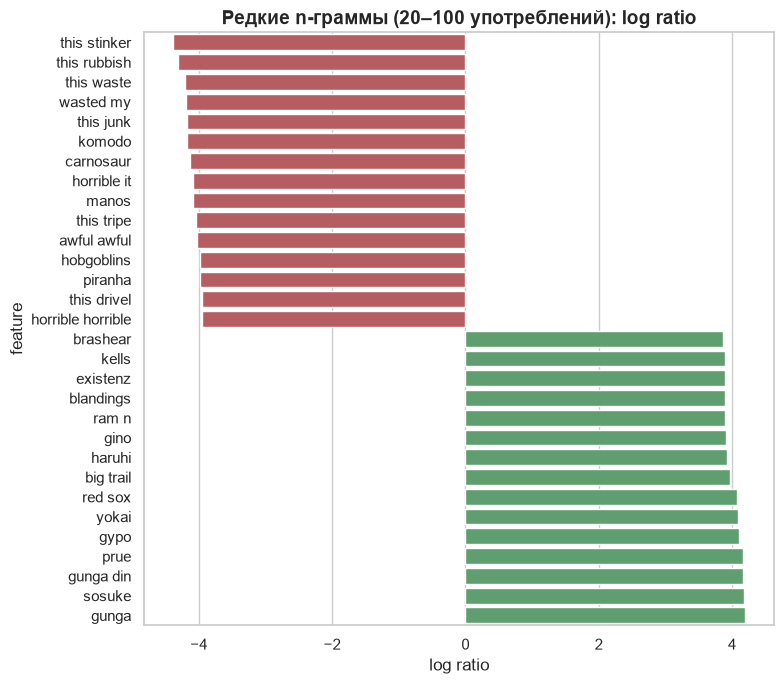

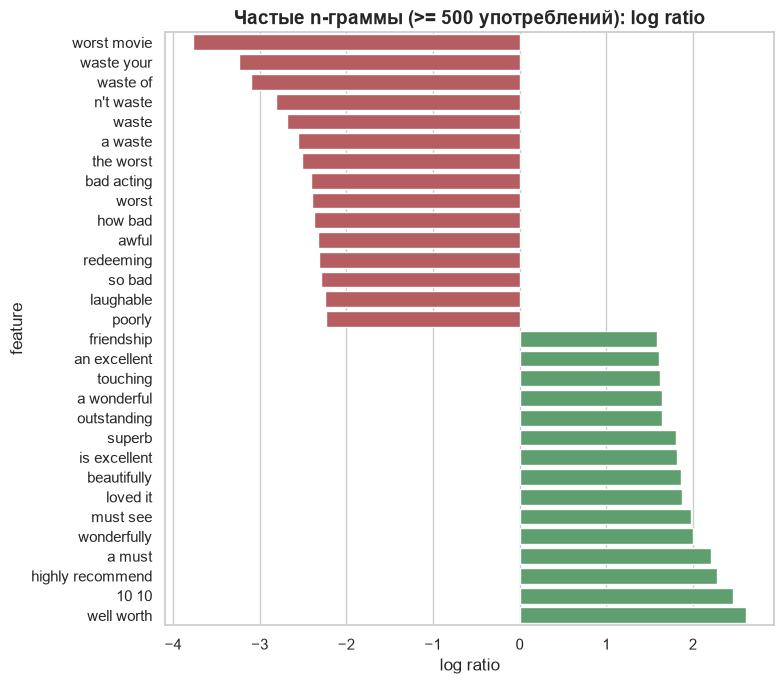

In [7]:
# log ratio без ограничения на частоту выдвигает редкие слова, встречающиеся почти только в одном классе
rare = ngrams[ngrams["total_count"] < 100]
_ = p.plot_signed_scores(rare["token"], rare["log_ratio"], "Редкие n-граммы (20–100 употреблений): log ratio", "log ratio")
# среди частых n-грамм видны общеоценочные маркеры
freq = ngrams[ngrams["total_count"] >= 500]
_ = p.plot_signed_scores(freq["token"], freq["log_ratio"], "Частые n-граммы (>= 500 употреблений): log ratio", "log ratio")

- По χ² самые информативные токены — оценочные слова (*bad, worst, great, awful, waste, terrible, excellent*), а также **`?` и отрицание `n't`** — признаки негативного отзыва. Значит, токенизатор правильно сохраняет их отдельными токенами.
- Среди лидеров есть биграммы — *the worst, waste of, must see, highly recommend, well worth, 10 10* (оценка «10 из 10»). Это довод в пользу n-грамм в моделях «мешка слов».
- У редких n-грамм самый большой log ratio — у **имён и названий**: *Komodo, Carnosaur, Manos* (известные «плохие» фильмы) против *Gunga Din, Sosuke, Raoul Walsh*. Они почти всегда встречаются в одном классе, и модель «мешка слов» может запоминать конкретные фильмы, а не тональность. Поэтому дальше пробуем пороги частоты (`min_df`) и отбор признаков по χ².

## Выводы EDA

1. После очистки осталось **49 577** отзывов (удалено 418 дубликатов и 5 коротких), в каждом ≥ 10 слов — требования ТЗ выполнены.
2. Классы сбалансированы — основные метрики F1 и accuracy, дополнительно ROC-AUC.
3. Отзывы длинные (медиана ~170 слов): для последовательностных моделей нужна обрезка (400 токенов для нейросетей, 256 субтокенов для трансформера).
4. Сильные признаки — оценочные слова, биграммы, отрицания и `?`. Удалять стоп-слова целиком рискованно: вместе с ними уходят отрицания.
5. Редкие имена собственные почти однозначно указывают на класс — это риск переобучения на конкретные фильмы.

Дальше: `baseline.ipynb` — бейзлайн и отбор токенов.